# 1. Loading the Datasets
## 1.1 Load the Wine Classification dataset from scikit-learn

In [1]:
import pandas as pd
from sklearn.datasets import load_wine

dataset = load_wine()

## 1.2 Create the data frames

In [2]:
X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
y = pd.Series(dataset.target, index=X.index, name="target")

In [3]:
print("First five rows")
display(X.head())

print("Dataset Shape:", X.shape)
print("Features Names:", X.columns.tolist())

class_count = y.value_counts().sort_index()

class_overview = pd.DataFrame({
    "target_label": class_count.index,
    "target_name": [dataset.target_names[label] for label in class_count.index],
    "sample_count": class_count.to_numpy(),
})

print("Target labels, class names, and sample counts");
display(class_overview)

First five rows


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


Dataset Shape: (178, 13)
Features Names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target labels, class names, and sample counts


,target_label,target_name,sample_count
0,0,class_0,59
1,1,class_1,71
2,2,class_2,48


## Dataset overview
The Wine dataset contains 178 samples and 13 numerical chemical-analysis features. The original scikit-learn labels are kept: 0 = `class_0` (59 samples), 1 = `class_1` (71 samples) and 2 = `class_2` (48 samples). The classes are reasonably balanced (≈33% / 40% / 27%), but the dataset is small, so the 10% validation subsets will contain only about 18 samples.

# 2. Dataset Quality Checks
## 2.1 Missing Values and Duplicates

In [4]:
data_for_checks = X.assign(target=y)

missing_counts = data_for_checks.isna().sum()
display(missing_counts.rename("missing_count").to_frame())

duplicate_count = data_for_checks.duplicated().sum()
print("Duplicate rows:", duplicate_count)

,missing_count
alcohol,0
malic_acid,0
ash,0
alcalinity_of_ash,0
magnesium,0
total_phenols,0
flavanoids,0
nonflavanoid_phenols,0
proanthocyanins,0
color_intensity,0


Duplicate rows: 0


The number of missing values is zero in every column and there are no duplicate rows, so no imputation or de-duplication is needed.

## 2.2 Potential Outliers

In [5]:
q1 = X.quantile(0.25)
q3 = X.quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

outside_bounds = X.lt(lower_bound) | X.gt(upper_bound)
outlier_counts = outside_bounds.sum().sort_values(ascending=False)

display(outlier_counts.rename("potential_outlier_count").to_frame())

,potential_outlier_count
alcalinity_of_ash,4
magnesium,4
color_intensity,4
malic_acid,3
ash,3
proanthocyanins,2
hue,1
alcohol,0
total_phenols,0
flavanoids,0


According to the IQR rule, only a few potential outliers exist: at most four per feature (`alcalinity_of_ash`, `magnesium` and `color_intensity`), and six features have none. These values are plausible chemical measurements, so they are not deleted or clipped.

Even a few extreme values can matter: KNN and K-Means use Euclidean distance, so a large value in a wide-range feature such as `magnesium` or `proline` can dominate the distance and shift centroids; StandardScaler's mean and standard deviation are also sensitive to them; Gaussian Naive Bayes variance estimates become larger. Decision Trees split on thresholds and are relatively robust to extreme values.

## 2.3 Data Types

In [6]:
display(X.dtypes.rename("dtype").to_frame())

numeric_count = X.select_dtypes(include="number").shape[1]
categorical_count = X.select_dtypes(
    include=["object", "string", "category", "bool"]
).shape[1]

print("Numerical features:", numeric_count)
print("Categorical features:", categorical_count)

,dtype
alcohol,float64
malic_acid,float64
ash,float64
alcalinity_of_ash,float64
magnesium,float64
total_phenols,float64
flavanoids,float64
nonflavanoid_phenols,float64
proanthocyanins,float64
color_intensity,float64


Numerical features: 13
Categorical features: 0


All 13 features are `float64` numerical features; there are no categorical features and no data-type concerns.

# 3. Exploratory Data Analysis (EDA)

## 3.1 Descriptive statistics

In [7]:
statistics = X.describe().T[
    ["mean", "std", "min", "25%", "50%", "75%", "max"]
].rename(columns={"25%": "Q1", "50%": "median", "75%": "Q3"})

display(statistics.round(3))

,mean,std,min,Q1,median,Q3,max
alcohol,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,5.058,2.318,1.28,3.220,4.690,6.200,13.00


The features are on very different scales: `proline` has a mean of about 747 and a maximum of 1,680, `magnesium` ranges from 70 to 162, while `hue` (0.48–1.71) and `nonflavanoid_phenols` (0.13–0.66) are below 2. `proline` (mean 746.9 vs. median 673.5) and `malic_acid` (mean 2.34 vs. median 1.87) are right-skewed.

## 3.2 Class distribution and correlations

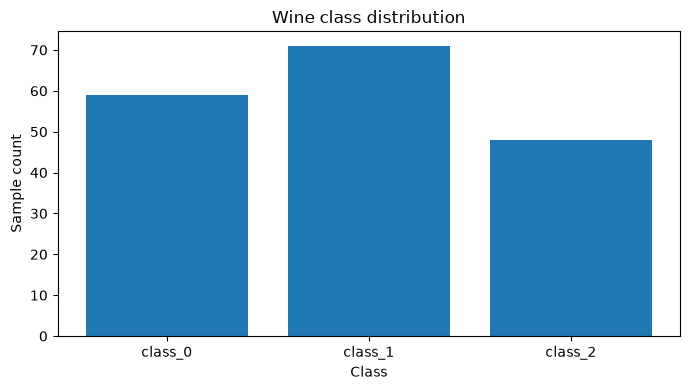

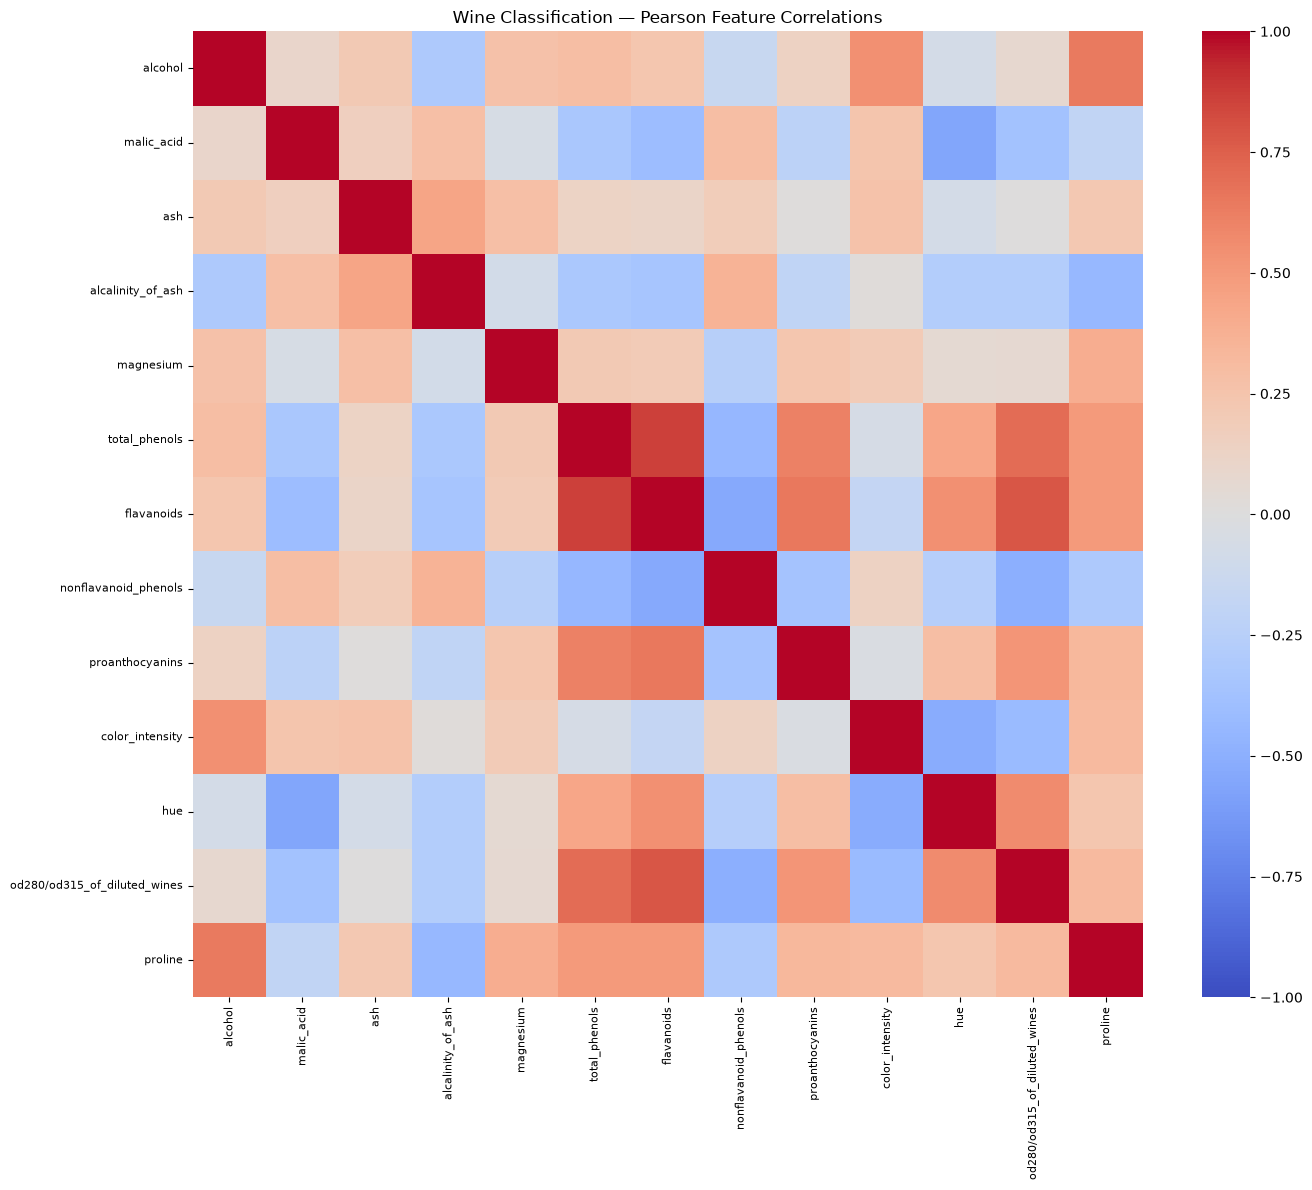

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import seaborn as sns

figure_dir = Path("figures/wine")
figure_dir.mkdir(parents=True, exist_ok=True)

class_counts = y.value_counts().sort_index()
class_names = [dataset.target_names[label] for label in class_counts.index]

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(class_names, class_counts.to_numpy())
ax.set(title="Wine class distribution", xlabel="Class", ylabel="Sample count")
fig.tight_layout()
fig.savefig(figure_dir / "class_distribution.png", dpi=150)
plt.show()

correlations = X.corr(method="pearson")

fig, ax = plt.subplots(figsize=(14, 12))
sns.heatmap(
    correlations,
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0,
    xticklabels=True,
    yticklabels=True,
    ax=ax,
)

ax.set_title("Wine Classification — Pearson Feature Correlations")
ax.tick_params(axis="x", labelrotation=90, labelsize=8)
ax.tick_params(axis="y", labelrotation=0, labelsize=8)

fig.tight_layout()
fig.savefig(figure_dir / "correlation_heatmap.png", dpi=150)
plt.show()

In [9]:
import numpy as np
import pandas as pd

row_indices, col_indices = np.triu_indices(len(correlations), k=1)

correlation_pairs = pd.DataFrame({
    "feature_1": correlations.index[row_indices],
    "feature_2": correlations.columns[col_indices],
    "pearson_r": correlations.to_numpy()[row_indices, col_indices],
})

correlation_pairs["absolute_r"] = correlation_pairs["pearson_r"].abs()
top_three_pairs = correlation_pairs.nlargest(3, "absolute_r")

display(top_three_pairs.reset_index(drop=True).round(3))

,feature_1,feature_2,pearson_r,absolute_r
0,total_phenols,flavanoids,0.865,0.865
1,flavanoids,od280/od315_of_diluted_wines,0.787,0.787
2,total_phenols,od280/od315_of_diluted_wines,0.700,0.700


**Interpretation (3.2).** The class distribution is fairly balanced (59 / 71 / 48), so stratification mainly keeps the small validation and test subsets representative.

The three strongest unique feature pairs (diagonal and mirrored pairs excluded) are:

1. `total_phenols` – `flavanoids` (r = 0.865)
2. `flavanoids` – `od280/od315_of_diluted_wines` (r = 0.787)
3. `total_phenols` – `od280/od315_of_diluted_wines` (r = 0.700)

Flavanoids are a subgroup of phenols, so the first pair is chemically expected; OD280/OD315 absorbance is also related to phenolic content.

## 3.3 Boxplots

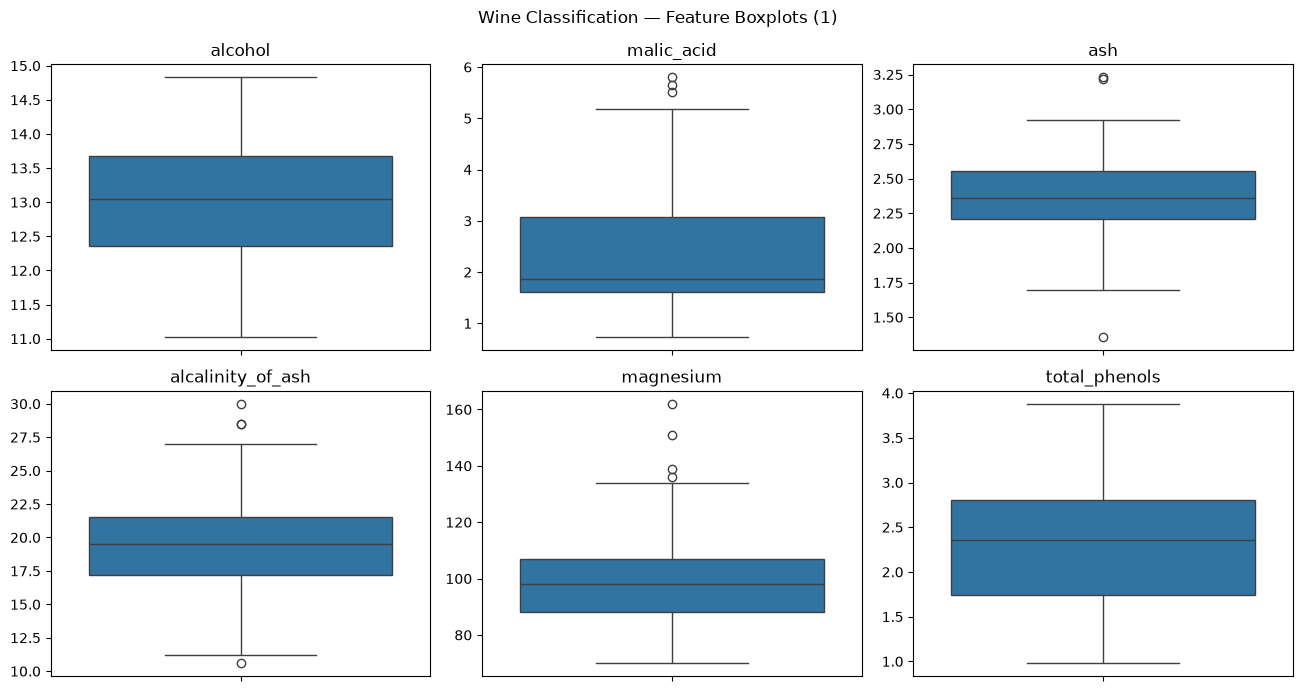

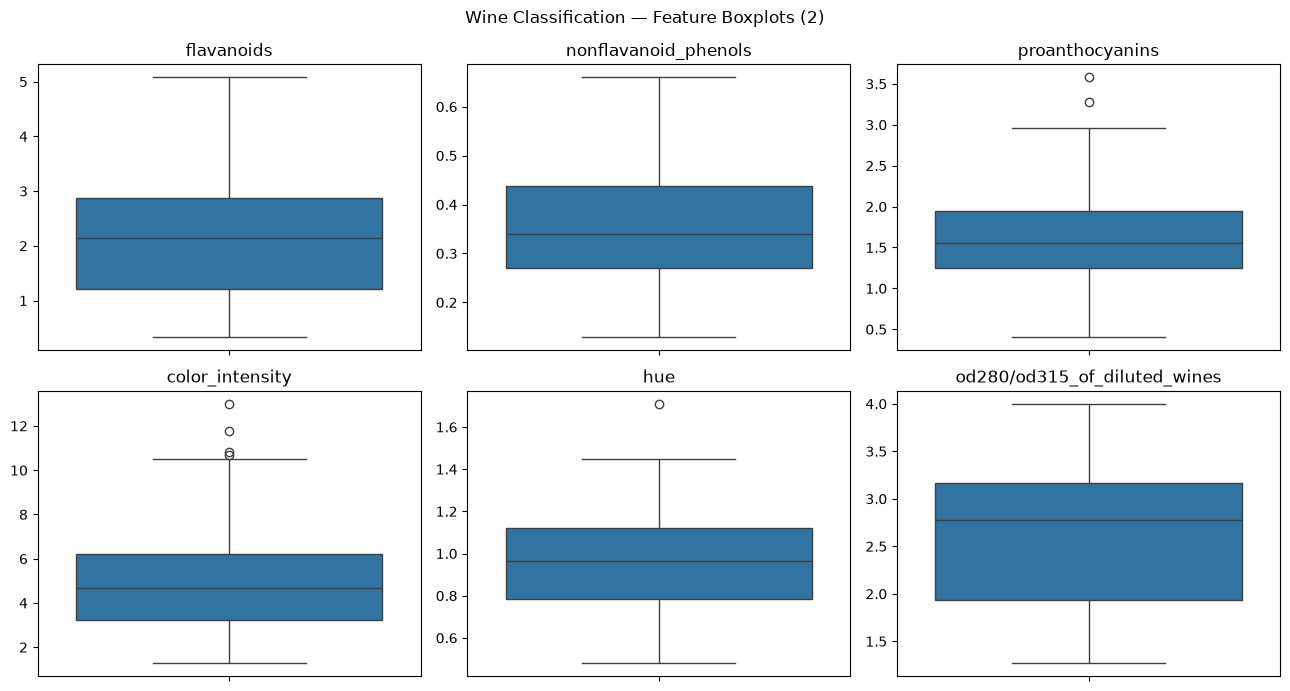

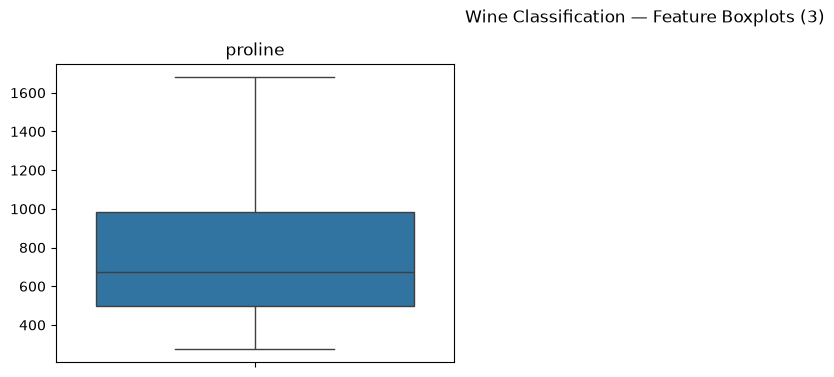

In [10]:
features_per_figure = 6

for start in range(0, X.shape[1], features_per_figure):
    features = X.columns[start:start + features_per_figure]
    group_number = start // features_per_figure + 1

    fig, axes = plt.subplots(2, 3, figsize=(13, 7))

    for ax, feature in zip(axes.flat, features):
        sns.boxplot(y=X[feature], ax=ax)
        ax.set_title(feature)
        ax.set_ylabel("")

    for ax in axes.flat[len(features):]:
        ax.set_visible(False)

    fig.suptitle(f"Wine Classification — Feature Boxplots ({group_number})")
    fig.tight_layout()
    fig.savefig(figure_dir / f"boxplots_{group_number}.png", dpi=150)
    plt.show()

**Interpretation (3.3).**

- **Very different ranges:** `proline` is in the hundreds to thousands and `magnesium` in the tens to over a hundred, while most other features are below about 15. Without scaling, `proline` would dominate Euclidean distances in KNN and K-Means.
- **Few outliers:** only a handful of points fall beyond the whiskers (for example in `magnesium`, `color_intensity` and `alcalinity_of_ash`), consistent with the IQR counts in Section 2.2.

# 4. Splitting the Datasets
## 4.1 Fix the test set and repeat the training/validation split

The 20% test set is reserved **once** with `random_state=42`. For each seed in `SEEDS = [42, 52, 62]` the remaining 80% is split into training and validation with `test_size=0.125` (0.125 × 80% = 10% of the full dataset). Pandas row indices are preserved, so every subset keeps the original row numbers.

In [11]:
from pathlib import Path
from sklearn.model_selection import train_test_split

DATASET_NAME = "wine"
SEEDS = [42, 52, 62]
TEST_SEED = 42
results_dir = Path("result")
results_dir.mkdir(parents=True, exist_ok=True)

X_rest, X_test, y_rest, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=TEST_SEED
)

splits = {}
for seed in SEEDS:
    X_train, X_val, y_train, y_val = train_test_split(
        X_rest, y_rest, test_size=0.125, stratify=y_rest, random_state=seed
    )
    splits[seed] = {
        "X_train": X_train, "X_val": X_val,
        "y_train": y_train, "y_val": y_val,
    }

print("Fixed test set size:", len(X_test))
for seed in SEEDS:
    print(f"Seed {seed}: train={len(splits[seed]['X_train'])}, val={len(splits[seed]['X_val'])}")

Fixed test set size: 36
Seed 42: train=124, val=18
Seed 52: train=124, val=18
Seed 62: train=124, val=18


## 4.2 Verify the split

In [12]:
class_labels = sorted(y.unique())
summary_rows = []

for seed in SEEDS:
    subsets = {
        "train": splits[seed]["y_train"],
        "validation": splits[seed]["y_val"],
        "test": y_test,
    }
    for subset_name, subset_y in subsets.items():
        row = {
            "seed": seed,
            "subset": subset_name,
            "n_samples": len(subset_y),
            "percent_of_full": round(len(subset_y) / len(y) * 100, 2),
        }
        for label in class_labels:
            row[f"class_{label}_{dataset.target_names[label]}"] = int((subset_y == label).sum())
        summary_rows.append(row)

split_summary = pd.DataFrame(summary_rows)
print("Wine Classification — split summary (3 subsets x 3 seeds)")
display(split_summary)

Wine Classification — split summary (3 subsets x 3 seeds)


,seed,subset,n_samples,percent_of_full,class_0_class_0,class_1_class_1,class_2_class_2
0,42,train,124,69.66,41,50,33
1,42,validation,18,10.11,6,7,5
2,42,test,36,20.22,12,14,10
3,52,train,124,69.66,41,50,33
4,52,validation,18,10.11,6,7,5
5,52,test,36,20.22,12,14,10
6,62,train,124,69.66,41,50,33
7,62,validation,18,10.11,6,7,5
8,62,test,36,20.22,12,14,10


In [13]:
test_index = set(X_test.index)
check_rows = []
for seed in SEEDS:
    train_index = set(splits[seed]["X_train"].index)
    val_index = set(splits[seed]["X_val"].index)
    check_rows.append({
        "seed": seed,
        "train∩val": len(train_index & val_index),
        "train∩test": len(train_index & test_index),
        "val∩test": len(val_index & test_index),
        "total_count": len(train_index) + len(val_index) + len(test_index),
        "equals_full_dataset": len(train_index | val_index | test_index) == len(X),
        "same_test_indices": set(y_test.index) == test_index,
    })
    assert len(train_index & val_index) == 0 and len(train_index & test_index) == 0 and len(val_index & test_index) == 0
    assert train_index | val_index | test_index == set(X.index)

display(pd.DataFrame(check_rows))

index_rows = []
for seed in SEEDS:
    for subset_name, subset_X in [("train", splits[seed]["X_train"]),
                                  ("validation", splits[seed]["X_val"]),
                                  ("test", X_test)]:
        index_rows += [{"dataset": DATASET_NAME, "seed": seed, "subset": subset_name, "row_index": int(i)}
                       for i in subset_X.index]
split_indices = pd.DataFrame(index_rows)
split_indices.to_csv(results_dir / f"{DATASET_NAME}_split_indices.csv", index=False)

print("First 10 test row indices:", sorted(X_test.index)[:10])
for seed in SEEDS:
    print(f"Seed {seed} — first 10 validation row indices:", sorted(splits[seed]["X_val"].index)[:10])

,seed,train∩val,train∩test,val∩test,total_count,equals_full_dataset,same_test_indices
0,42,0,0,0,178,True,True
1,52,0,0,0,178,True,True
2,62,0,0,0,178,True,True


First 10 test row indices: [7, 10, 14, 18, 20, 22, 28, 38, 42, 48]
Seed 42 — first 10 validation row indices: [0, 1, 4, 6, 33, 35, 79, 86, 89, 97]
Seed 52 — first 10 validation row indices: [2, 31, 33, 34, 40, 45, 63, 69, 70, 91]
Seed 62 — first 10 validation row indices: [2, 9, 15, 25, 27, 29, 67, 68, 101, 107]


**Interpretation (4).** Out of 178 samples, 124 are used for training, 18 for validation and 36 for testing in every repetition. Stratification keeps the class proportions almost identical across subsets (41 / 50 / 33 samples of classes 0 / 1 / 2 in training, 6 / 7 / 5 in validation and 12 / 14 / 10 in test). The three seeds change only which samples are used for training versus validation.

# 5. Data Preprocessing and Scaling
## 5.1 Handle missing values, if present

In [14]:
total_missing = int(X.isna().sum().sum())
print("Total missing values in the dataset:", total_missing)
if total_missing == 0:
    print("No missing values exist, so no imputation step is added.")

Total missing values in the dataset: 0
No missing values exist, so no imputation step is added.


## 5.2 Select one scaler
**StandardScaler** is selected before running the experiments and is used for both datasets and all three seeds.

## 5.3 Fit and apply the scaler correctly

In [15]:
from sklearn.preprocessing import StandardScaler

scalers = {}
for seed in SEEDS:
    scaler = StandardScaler()
    scaler.fit(splits[seed]["X_train"])
    scalers[seed] = scaler

    splits[seed]["X_train_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_train"]),
        index=splits[seed]["X_train"].index, columns=X.columns,
    )
    splits[seed]["X_val_scaled"] = pd.DataFrame(
        scaler.transform(splits[seed]["X_val"]),
        index=splits[seed]["X_val"].index, columns=X.columns,
    )

X_test_scaled = pd.DataFrame(
    scalers[TEST_SEED].transform(X_test), index=X_test.index, columns=X.columns
)

print("Fitted scalers:", list(scalers.keys()))

Fitted scalers: [42, 52, 62]


In [16]:
print("Wine Classification — seed 42 training data BEFORE scaling")
display(splits[TEST_SEED]["X_train"].head().round(3))

print("Wine Classification — seed 42 training data AFTER StandardScaler")
display(splits[TEST_SEED]["X_train_scaled"].head().round(3))

scaled_check = pd.DataFrame({
    "train_mean_after": splits[TEST_SEED]["X_train_scaled"].mean(),
    "train_std_after": splits[TEST_SEED]["X_train_scaled"].std(ddof=0),
}).round(3)
print("Mean and standard deviation of scaled seed-42 training features (first 5 features)")
display(scaled_check.head())

Wine Classification — seed 42 training data BEFORE scaling


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,12.96,3.45,2.35,18.5,106.0,1.39,0.70,0.40,0.94,5.28,0.68,1.75,675.0
148,13.32,3.24,2.38,21.5,92.0,1.93,0.76,0.45,1.25,8.42,0.55,1.62,650.0
116,11.82,1.47,1.99,20.8,86.0,1.98,1.60,0.30,1.53,1.95,0.95,3.33,495.0
122,12.42,4.43,2.73,26.5,102.0,2.20,2.13,0.43,1.71,2.08,0.92,3.12,365.0
115,11.03,1.51,2.20,21.5,85.0,2.46,2.17,0.52,2.01,1.90,1.71,2.87,407.0


Wine Classification — seed 42 training data AFTER StandardScaler


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
163,-0.018,1.089,-0.040,-0.308,0.433,-1.343,-1.322,0.353,-1.118,0.126,-1.227,-1.224,-0.209
148,0.440,0.892,0.073,0.609,-0.506,-0.491,-1.260,0.770,-0.572,1.512,-1.811,-1.415,-0.291
116,-1.465,-0.772,-1.397,0.395,-0.908,-0.412,-0.387,-0.482,-0.079,-1.344,-0.013,1.098,-0.800
122,-0.703,2.010,1.392,2.139,0.165,-0.065,0.165,0.603,0.238,-1.287,-0.147,0.789,-1.226
115,-2.469,-0.734,-0.605,0.609,-0.975,0.345,0.206,1.354,0.766,-1.367,3.405,0.422,-1.089


Mean and standard deviation of scaled seed-42 training features (first 5 features)


,train_mean_after,train_std_after
alcohol,-0.0,1.0
malic_acid,-0.0,1.0
ash,-0.0,1.0
alcalinity_of_ash,0.0,1.0
magnesium,-0.0,1.0


**Interpretation (5).** There are no missing values, so no imputer is used. Validation subsets are transformed with the scaler of the same seed, and the fixed test set is transformed only with the seed-42 scaler. After scaling, the seed-42 training features have mean 0 and standard deviation 1.

# 6. Preparing the Two Data Representations

In [17]:
representations = {}
for seed in SEEDS:
    representations[seed] = {
        "unscaled": {"X_train": splits[seed]["X_train"], "X_val": splits[seed]["X_val"]},
        "scaled": {"X_train": splits[seed]["X_train_scaled"], "X_val": splits[seed]["X_val_scaled"]},
        "y_train": splits[seed]["y_train"],
        "y_val": splits[seed]["y_val"],
    }
    assert representations[seed]["unscaled"]["X_train"].index.equals(representations[seed]["scaled"]["X_train"].index)
    assert representations[seed]["unscaled"]["X_val"].index.equals(representations[seed]["scaled"]["X_val"].index)

test_representations = {"unscaled": X_test, "scaled": X_test_scaled}

overview = pd.DataFrame([
    {"seed": seed, "representation": rep,
     "train_shape": representations[seed][rep]["X_train"].shape,
     "val_shape": representations[seed][rep]["X_val"].shape}
    for seed in SEEDS for rep in ["unscaled", "scaled"]
])
display(overview)

,seed,representation,train_shape,val_shape
0,42,unscaled,"(124, 13)","(18, 13)"
1,42,scaled,"(124, 13)","(18, 13)"
2,52,unscaled,"(124, 13)","(18, 13)"
3,52,scaled,"(124, 13)","(18, 13)"
4,62,unscaled,"(124, 13)","(18, 13)"
5,62,scaled,"(124, 13)","(18, 13)"


**Interpretation (6).** Each seed now has two representations with identical sample indices and feature sets: unscaled and scaled.

# 7. Training the Classification Models
## 7.1 Required experiments
Per dataset: 11 settings × 2 representations × 3 seeds = **66 classifier runs**.

In [18]:
import platform
import sklearn
import matplotlib
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

package_versions = {
    "python": platform.python_version(),
    "scikit-learn": sklearn.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "matplotlib": matplotlib.__version__,
    "seaborn": sns.__version__,
}
print("Package versions:", package_versions)

DEPTHS = [2, 3, 5, 10, None]
NEIGHBORS = [1, 3, 5, 7, 11]
REPRESENTATIONS = ["unscaled", "scaled"]


def build_configurations(seed):
    configs = []
    for depth in DEPTHS:
        configs.append({
            "algorithm": "decision_tree", "param_name": "max_depth", "param_value": str(depth),
            "short": f"dt_depth{depth}",
            "model": DecisionTreeClassifier(max_depth=depth, random_state=seed),
        })
    for k in NEIGHBORS:
        configs.append({
            "algorithm": "knn", "param_name": "n_neighbors", "param_value": str(k),
            "short": f"knn_k{k}",
            "model": KNeighborsClassifier(n_neighbors=k, weights="uniform", metric="euclidean"),
        })
    configs.append({
        "algorithm": "gaussian_nb", "param_name": "default", "param_value": "default",
        "short": "gnb_default", "model": GaussianNB(),
    })
    return configs

Package versions: {'python': '3.11.16', 'scikit-learn': '1.9.1', 'pandas': '3.0.6', 'numpy': '2.4.6', 'matplotlib': '3.11.2', 'seaborn': '0.13.2'}


In [19]:
class_labels = sorted(y.unique())


def compute_roc_auc(model, X_eval, y_eval):
    probabilities = model.predict_proba(X_eval)
    model_classes = list(model.classes_)
    if DATASET_NAME == "breast_cancer":
        malignant_column = model_classes.index(0)
        y_binary = (y_eval == 0).astype(int)
        return roc_auc_score(y_binary, probabilities[:, malignant_column])
    assert model_classes == class_labels
    return roc_auc_score(y_eval, probabilities, multi_class="ovr",
                         average="macro", labels=class_labels)


def undefined_metric_classes(y_true, y_pred):
    no_predictions = [c for c in class_labels if (y_pred == c).sum() == 0]
    no_true_samples = [c for c in class_labels if (y_true == c).sum() == 0]
    return no_predictions, no_true_samples


def evaluate(model, X_eval, y_eval):
    y_pred = model.predict(X_eval)
    undefined_precision, undefined_recall = undefined_metric_classes(y_eval, y_pred)
    return {
        "accuracy": accuracy_score(y_eval, y_pred),
        "macro_precision": precision_score(y_eval, y_pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_eval, y_pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_eval, y_pred, average="macro", zero_division=0),
        "roc_auc": compute_roc_auc(model, X_eval, y_eval),
        "undefined_precision_classes": str(undefined_precision) if undefined_precision else "",
        "undefined_recall_classes": str(undefined_recall) if undefined_recall else "",
    }

## 7.2 Record and compare the experiments

In [20]:
run_records = []
fitted_models_seed42 = {}

for seed in SEEDS:
    y_train_seed = representations[seed]["y_train"]
    y_val_seed = representations[seed]["y_val"]
    for representation in REPRESENTATIONS:
        X_train_rep = representations[seed][representation]["X_train"]
        X_val_rep = representations[seed][representation]["X_val"]
        for config in build_configurations(seed):
            model = config["model"]
            model.fit(X_train_rep, y_train_seed)

            algo_short, param_short = config["short"].split("_", 1)
            config_id = f"{DATASET_NAME}_{algo_short}_{representation}_{param_short}"
            run_id = f"{config_id}_s{seed}"

            train_pred = model.predict(X_train_rep)
            val_metrics = evaluate(model, X_val_rep, y_val_seed)

            run_records.append({
                "dataset": DATASET_NAME,
                "run_id": run_id,
                "config_id": config_id,
                "seed": seed,
                "algorithm": config["algorithm"],
                "representation": representation,
                "param_name": config["param_name"],
                "param_value": config["param_value"],
                "n_train": len(y_train_seed),
                "n_val": len(y_val_seed),
                "train_accuracy": accuracy_score(y_train_seed, train_pred),
                "train_macro_f1": f1_score(y_train_seed, train_pred, average="macro", zero_division=0),
                **{f"val_{k}": v for k, v in val_metrics.items()},
            })
            if seed == TEST_SEED:
                fitted_models_seed42[config_id] = model

runs = pd.DataFrame(run_records)
runs.to_csv(results_dir / f"{DATASET_NAME}_classifier_runs.csv", index=False)

print("Number of classifier runs:", len(runs))
print("Fitted seed-42 models kept:", len(fitted_models_seed42))
print("Runs with undefined precision before zero_division:",
      int((runs["val_undefined_precision_classes"] != "").sum()))
print("Runs with undefined recall before zero_division:",
      int((runs["val_undefined_recall_classes"] != "").sum()))

Number of classifier runs: 66
Fitted seed-42 models kept: 22
Runs with undefined precision before zero_division: 0
Runs with undefined recall before zero_division: 0


# 8. Measuring Validation Performance
## 8.1 Required metrics
Every run is evaluated on its own validation subset with accuracy, macro precision, macro recall, macro F1 (`zero_division=0`) and ROC-AUC. For Wine, ROC-AUC uses the class-probability matrix with `multi_class='ovr'` and `average='macro'`.

## 8.2 Comparison tables and model selection
### Run-level validation table (66 rows)

In [21]:
metric_columns = ["train_accuracy", "train_macro_f1", "val_accuracy", "val_macro_precision",
                  "val_macro_recall", "val_macro_f1", "val_roc_auc"]
run_table = runs[["run_id", "seed", "algorithm", "representation", "param_name", "param_value"]
                 + metric_columns]
print("Wine Classification — run-level validation table:", run_table.shape)
with pd.option_context("display.max_rows", 100):
    display(run_table.round(4))

Wine Classification — run-level validation table: (66, 13)


,run_id,seed,algorithm,representation,param_name,param_value,train_accuracy,train_macro_f1,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_roc_auc
0,wine_dt_unscaled_depth2_s42,42,decision_tree,unscaled,max_depth,2,0.9355,0.9297,0.8333,0.8631,0.8111,0.8175,0.9106
1,wine_dt_unscaled_depth3_s42,42,decision_tree,unscaled,max_depth,3,0.9919,0.9926,0.9444,0.9583,0.9444,0.9475,0.9686
2,wine_dt_unscaled_depth5_s42,42,decision_tree,unscaled,max_depth,5,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
3,wine_dt_unscaled_depth10_s42,42,decision_tree,unscaled,max_depth,10,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
4,wine_dt_unscaled_depthNone_s42,42,decision_tree,unscaled,max_depth,None,1.0000,1.0000,0.9444,0.9583,0.9444,0.9475,0.9571
5,wine_knn_unscaled_k1_s42,42,knn,unscaled,n_neighbors,1,1.0000,1.0000,0.6667,0.6750,0.6603,0.6646,0.7452
6,wine_knn_unscaled_k3_s42,42,knn,unscaled,n_neighbors,3,0.8468,0.8415,0.6111,0.6111,0.6016,0.6041,0.8003
7,wine_knn_unscaled_k5_s42,42,knn,unscaled,n_neighbors,5,0.7984,0.7837,0.7222,0.7159,0.7159,0.7128,0.8759
8,wine_knn_unscaled_k7_s42,42,knn,unscaled,n_neighbors,7,0.8145,0.8071,0.6667,0.6714,0.6683,0.6605,0.8405
9,wine_knn_unscaled_k11_s42,42,knn,unscaled,n_neighbors,11,0.7500,0.7405,0.6111,0.6159,0.6016,0.5998,0.8198


### Summary across the three seeds (22 rows, mean and sample standard deviation)

In [22]:
group_columns = ["config_id", "algorithm", "representation", "param_name", "param_value"]
summary = runs.groupby(group_columns, sort=False)[metric_columns].agg(["mean", lambda s: s.std(ddof=1)])
summary.columns = [f"{metric}_{'mean' if stat == 'mean' else 'std'}" for metric, stat in summary.columns]
summary = summary.reset_index()
summary.insert(0, "dataset", DATASET_NAME)
summary["n_seeds"] = runs.groupby("config_id", sort=False).size().to_numpy()
summary["train_val_f1_gap"] = summary["train_macro_f1_mean"] - summary["val_macro_f1_mean"]

ranked = summary.sort_values(
    ["val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std", "config_id"],
    ascending=[False, False, True, True],
).reset_index(drop=True)
selected_config_id = ranked.loc[0, "config_id"]
summary["selected"] = summary["config_id"] == selected_config_id
summary.to_csv(results_dir / f"{DATASET_NAME}_classifier_summary.csv", index=False)

display_columns = ["config_id", "algorithm", "representation", "param_value",
                   "train_macro_f1_mean", "train_macro_f1_std",
                   "val_accuracy_mean", "val_accuracy_std",
                   "val_macro_precision_mean", "val_macro_recall_mean",
                   "val_macro_f1_mean", "val_macro_f1_std",
                   "val_roc_auc_mean", "val_roc_auc_std", "train_val_f1_gap", "selected"]
print("Wine Classification — 22-row summary (mean and std with ddof=1 across 3 seeds)")
with pd.option_context("display.max_rows", 30):
    display(summary[display_columns].round(4))

print("Top 5 configurations by the selection rule:")
display(ranked[["config_id", "val_macro_f1_mean", "val_accuracy_mean", "val_macro_f1_std"]].head(5).round(4))
print("SELECTED CONFIGURATION:", selected_config_id)

Wine Classification — 22-row summary (mean and std with ddof=1 across 3 seeds)


,config_id,algorithm,representation,param_value,train_macro_f1_mean,train_macro_f1_std,val_accuracy_mean,val_accuracy_std,val_macro_precision_mean,val_macro_recall_mean,val_macro_f1_mean,val_macro_f1_std,val_roc_auc_mean,val_roc_auc_std,train_val_f1_gap,selected
0,wine_dt_unscaled_depth2,decision_tree,unscaled,2,0.9365,0.0106,0.8519,0.0321,0.8724,0.8487,0.8481,0.0365,0.9050,0.0219,0.0883,False
1,wine_dt_unscaled_depth3,decision_tree,unscaled,3,0.9926,0.0000,0.9444,0.0556,0.9614,0.9407,0.9462,0.0545,0.9611,0.0431,0.0464,False
2,wine_dt_unscaled_depth5,decision_tree,unscaled,5,1.0000,0.0000,0.9444,0.0556,0.9614,0.9407,0.9462,0.0545,0.9552,0.0457,0.0538,False
3,wine_dt_unscaled_depth10,decision_tree,unscaled,10,1.0000,0.0000,0.9444,0.0556,0.9614,0.9407,0.9462,0.0545,0.9552,0.0457,0.0538,False
4,wine_dt_unscaled_depthNone,decision_tree,unscaled,None,1.0000,0.0000,0.9444,0.0556,0.9614,0.9407,0.9462,0.0545,0.9552,0.0457,0.0538,False
5,wine_knn_unscaled_k1,knn,unscaled,1,1.0000,0.0000,0.7037,0.0321,0.6886,0.6836,0.6714,0.0226,0.7654,0.0181,0.3286,False
6,wine_knn_unscaled_k3,knn,unscaled,3,0.8294,0.0134,0.6667,0.0556,0.6614,0.6519,0.6456,0.0429,0.8333,0.0311,0.1838,False
7,wine_knn_unscaled_k5,knn,unscaled,5,0.7739,0.0091,0.7037,0.0321,0.7280,0.6862,0.6667,0.0399,0.8645,0.0115,0.1072,False
8,wine_knn_unscaled_k7,knn,unscaled,7,0.7804,0.0231,0.6667,0.0000,0.6471,0.6545,0.6356,0.0316,0.8459,0.0084,0.1448,False
9,wine_knn_unscaled_k11,knn,unscaled,11,0.7309,0.0083,0.6296,0.0321,0.6148,0.6138,0.6005,0.0010,0.8216,0.0254,0.1304,False


Top 5 configurations by the selection rule:


,config_id,val_macro_f1_mean,val_accuracy_mean,val_macro_f1_std
0,wine_knn_scaled_k11,0.9814,0.9815,0.0323
1,wine_knn_scaled_k5,0.9814,0.9815,0.0323
2,wine_knn_scaled_k7,0.9814,0.9815,0.0323
3,wine_knn_scaled_k1,0.9658,0.9630,0.0296
4,wine_gnb_scaled_default,0.9638,0.9630,0.0314


SELECTED CONFIGURATION: wine_knn_scaled_k11


In [23]:
scaling_effect = summary.pivot_table(
    index=["algorithm", "param_value"], columns="representation", values="val_macro_f1_mean"
)[["unscaled", "scaled"]]
scaling_effect["difference_scaled_minus_unscaled"] = scaling_effect["scaled"] - scaling_effect["unscaled"]
print("Mean validation macro-F1 by representation")
display(scaling_effect.round(4))

Mean validation macro-F1 by representation


representation             unscaled  scaled  difference_scaled_minus_unscaled
algorithm     param_value                                                    
decision_tree 10             0.9462  0.9462                            0.0000
              2              0.8481  0.8481                            0.0000
              3              0.9462  0.9462                            0.0000
              5              0.9462  0.9462                            0.0000
              None           0.9462  0.9462                            0.0000
gaussian_nb   default        0.9638  0.9638                            0.0000
knn           1              0.6714  0.9658                            0.2944
              11             0.6005  0.9814                            0.3809
              3              0.6456  0.9457                            0.3002
              5              0.6667  0.9814                            0.3146
              7              0.6356  0.9814                            0.3458

### Parameter-comparison figures

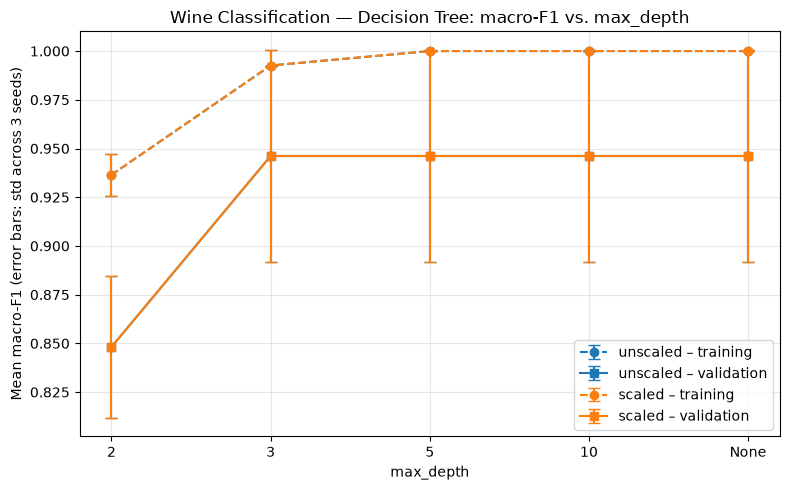

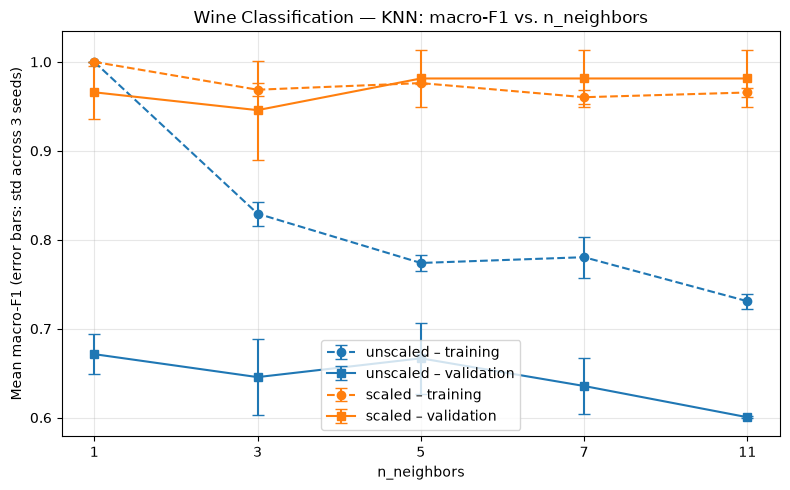

In [24]:
def plot_parameter_comparison(algorithm, param_order, param_label, file_name, plot_title):
    fig, ax = plt.subplots(figsize=(8, 5))
    x_positions = np.arange(len(param_order))
    styles = {"unscaled": "tab:blue", "scaled": "tab:orange"}
    for representation in REPRESENTATIONS:
        part = (summary[(summary["algorithm"] == algorithm) & (summary["representation"] == representation)]
                .set_index("param_value").loc[param_order])
        ax.errorbar(x_positions, part["train_macro_f1_mean"], yerr=part["train_macro_f1_std"],
                    marker="o", linestyle="--", capsize=4, color=styles[representation],
                    label=f"{representation} – training")
        ax.errorbar(x_positions, part["val_macro_f1_mean"], yerr=part["val_macro_f1_std"],
                    marker="s", linestyle="-", capsize=4, color=styles[representation],
                    label=f"{representation} – validation")
    ax.set_xticks(x_positions)
    ax.set_xticklabels(param_order)
    ax.set(xlabel=param_label, ylabel="Mean macro-F1 (error bars: std across 3 seeds)", title=plot_title)
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    fig.savefig(figure_dir / file_name, dpi=150)
    plt.show()


plot_parameter_comparison("decision_tree", [str(d) for d in DEPTHS], "max_depth",
                          "decision_tree_depth_comparison.png",
                          "Wine Classification — Decision Tree: macro-F1 vs. max_depth")
plot_parameter_comparison("knn", [str(k) for k in NEIGHBORS], "n_neighbors",
                          "knn_neighbors_comparison.png",
                          "Wine Classification — KNN: macro-F1 vs. n_neighbors")

**Interpretation (8.2).**

- **Selected configuration:** `wine_knn_scaled_k5`, `wine_knn_scaled_k7` and `wine_knn_scaled_k11` are tied on mean validation macro-F1 (0.9814), mean validation accuracy (0.9815) and macro-F1 standard deviation (0.0323). Following the tie-break rule, the alphabetically first configuration ID, **`wine_knn_scaled_k11`**, is selected.
- **Scaling effect:** KNN is strongly affected by scaling. Mean validation macro-F1 increases from 0.6005 to 0.9814 for k = 11, from 0.6667 to 0.9814 for k = 5 and from 0.6714 to 0.9658 for k = 1. Without scaling, `proline` and `magnesium` dominate the Euclidean distance. Decision Tree and Gaussian Naive Bayes give identical results for both representations.
- **Tree depth:** depth 2 is too shallow (validation macro-F1 0.8481). From depth 3 onwards the validation score stays at 0.9462 while training macro-F1 reaches 1.0, so deeper trees add no validation benefit.
- **Neighbour count:** on scaled data validation macro-F1 is 0.9658 at k = 1, drops slightly at k = 3 (0.9457) and is highest for k = 5, 7 and 11 (0.9814). On unscaled data larger k does not help (0.6714 → 0.6005), so a larger k is not always better.
- **Variability across seeds:** with only 18 validation samples, one error changes validation accuracy by about 5.6 percentage points. Standard deviations of validation macro-F1 reach about 0.055, so the top configurations are not clearly separated.

# 9. Evaluating the Selected Model on the Test Set
## 9.1 Final performance metrics

In [25]:
from sklearn.metrics import classification_report, confusion_matrix, roc_curve

selected_row = summary.loc[summary["config_id"] == selected_config_id].iloc[0]
selected_representation = selected_row["representation"]
selected_model = fitted_models_seed42[selected_config_id]
X_test_selected = test_representations[selected_representation]

test_metrics = evaluate(selected_model, X_test_selected, y_test)
y_test_pred = selected_model.predict(X_test_selected)
y_test_proba = selected_model.predict_proba(X_test_selected)

classifier_test = pd.DataFrame([{
    "dataset": DATASET_NAME,
    "selected_configuration": selected_config_id,
    "evaluation_seed": TEST_SEED,
    "val_macro_f1_mean": selected_row["val_macro_f1_mean"],
    "val_macro_f1_std": selected_row["val_macro_f1_std"],
    "test_accuracy": test_metrics["accuracy"],
    "test_macro_precision": test_metrics["macro_precision"],
    "test_macro_recall": test_metrics["macro_recall"],
    "test_macro_f1": test_metrics["macro_f1"],
    "test_roc_auc": test_metrics["roc_auc"],
}])
classifier_test.to_csv(results_dir / f"{DATASET_NAME}_classifier_test.csv", index=False)
print("Wine Classification — final test evaluation (seed 42)")
display(classifier_test.round(4))
print("Undefined precision classes before zero_division:", test_metrics["undefined_precision_classes"] or "none")
print("Undefined recall classes before zero_division:", test_metrics["undefined_recall_classes"] or "none")

Wine Classification — final test evaluation (seed 42)


,dataset,selected_configuration,evaluation_seed,val_macro_f1_mean,val_macro_f1_std,test_accuracy,test_macro_precision,test_macro_recall,test_macro_f1,test_roc_auc
0,wine,wine_knn_scaled_k11,42,0.9814,0.0323,1.0,1.0,1.0,1.0,1.0


Undefined precision classes before zero_division: none
Undefined recall classes before zero_division: none


**Interpretation (9.1).** The selected `wine_knn_scaled_k11` model classifies all 36 test samples correctly (accuracy, macro-F1 and ROC-AUC all equal 1.0). This is slightly higher than its mean validation macro-F1 (0.9814 ± 0.0323).

In [26]:
class_names = [str(dataset.target_names[label]) for label in class_labels]
print("Wine Classification — test classification report:", selected_config_id)
print(classification_report(y_test, y_test_pred, labels=class_labels,
                            target_names=class_names, digits=4, zero_division=0))
report_df = pd.DataFrame(classification_report(
    y_test, y_test_pred, labels=class_labels, target_names=class_names,
    output_dict=True, zero_division=0)).T

Wine Classification — test classification report: wine_knn_scaled_k11
              precision    recall  f1-score   support

     class_0     1.0000    1.0000    1.0000        12
     class_1     1.0000    1.0000    1.0000        14
     class_2     1.0000    1.0000    1.0000        10

    accuracy                         1.0000        36
   macro avg     1.0000    1.0000    1.0000        36
weighted avg     1.0000    1.0000    1.0000        36



## 9.2 Confusion matrix

,Predicted class_0,Predicted class_1,Predicted class_2
Actual class_0,12,0,0
Actual class_1,0,14,0
Actual class_2,0,0,10


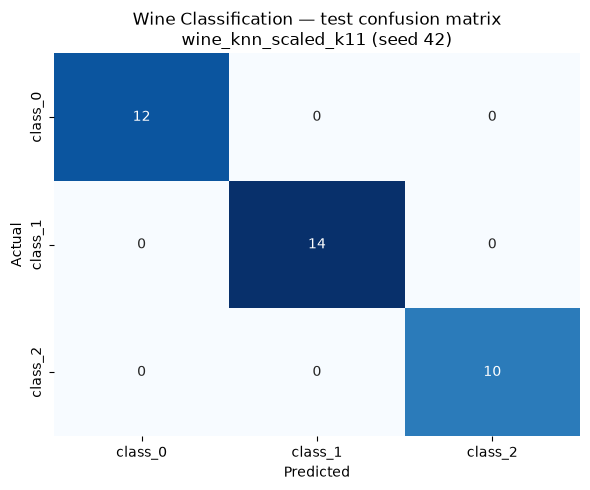

In [27]:
cm = confusion_matrix(y_test, y_test_pred, labels=class_labels)
cm_df = pd.DataFrame(cm,
                     index=[f"Actual {n}" for n in class_names],
                     columns=[f"Predicted {n}" for n in class_names])
display(cm_df)

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=class_names, yticklabels=class_names, ax=ax)
ax.set(xlabel="Predicted", ylabel="Actual",
       title=f"Wine Classification — test confusion matrix\n{selected_config_id} (seed 42)")
fig.tight_layout()
fig.savefig(figure_dir / "confusion_matrix_test.png", dpi=150)
plt.show()

In [28]:
off_diagonal = cm.copy()
np.fill_diagonal(off_diagonal, 0)
if off_diagonal.sum() == 0:
    print("The selected classifier makes no test errors: all off-diagonal cells are zero.")
else:
    i, j = np.unravel_index(off_diagonal.argmax(), off_diagonal.shape)
    print(f"Largest off-diagonal confusion: {off_diagonal[i, j]} sample(s) of actual {class_names[i]} predicted as {class_names[j]}")

check_class = 1
TP = cm[check_class, check_class]
FP = cm[:, check_class].sum() - TP
FN = cm[check_class, :].sum() - TP
TN = cm.sum() - TP - FP - FN
print(f"class_{check_class} vs rest: TP={TP}, FP={FP}, FN={FN}, TN={TN}")

precision_manual = TP / (TP + FP) if (TP + FP) > 0 else float("nan")
recall_manual = TP / (TP + FN) if (TP + FN) > 0 else float("nan")
f1_manual = (2 * precision_manual * recall_manual / (precision_manual + recall_manual)
             if (precision_manual + recall_manual) > 0 else float("nan"))

print(f"Precision = TP / (TP + FP) = {TP} / ({TP} + {FP}) = {precision_manual:.4f}")
print(f"Recall    = TP / (TP + FN) = {TP} / ({TP} + {FN}) = {recall_manual:.4f}")
print(f"F1        = 2·P·R / (P + R) = {f1_manual:.4f}")

manual_check = pd.DataFrame({
    "manual": [precision_manual, recall_manual, f1_manual],
    f"classification_report (class_{check_class} row)":
        report_df.loc[f"class_{check_class}", ["precision", "recall", "f1-score"]].to_numpy(),
}, index=["precision", "recall", "f1"]).astype(float)
manual_check["match"] = np.isclose(manual_check.iloc[:, 0], manual_check.iloc[:, 1])
display(manual_check.round(4))

The selected classifier makes no test errors: all off-diagonal cells are zero.
class_1 vs rest: TP=14, FP=0, FN=0, TN=22
Precision = TP / (TP + FP) = 14 / (14 + 0) = 1.0000
Recall    = TP / (TP + FN) = 14 / (14 + 0) = 1.0000
F1        = 2·P·R / (P + R) = 1.0000


,manual,classification_report (class_1 row),match
precision,1.0,1.0,True
recall,1.0,1.0,True
f1,1.0,1.0,True


**Interpretation (9.2).** The complete 3 × 3 matrix is diagonal: 12 / 14 / 10 samples of classes 0 / 1 / 2 are all correctly classified, so **there is no off-diagonal confusion** to explain. For the manual check, class_1 is treated as positive and the other classes as negative (one-vs-rest): TP = 14, FP = 0, FN = 0 and TN = 22, giving precision = 14 / 14 = 1.0000, recall = 14 / 14 = 1.0000 and F1 = 1.0000, which match the class_1 row of the classification report.

## 9.3 ROC curves (one-vs-rest)

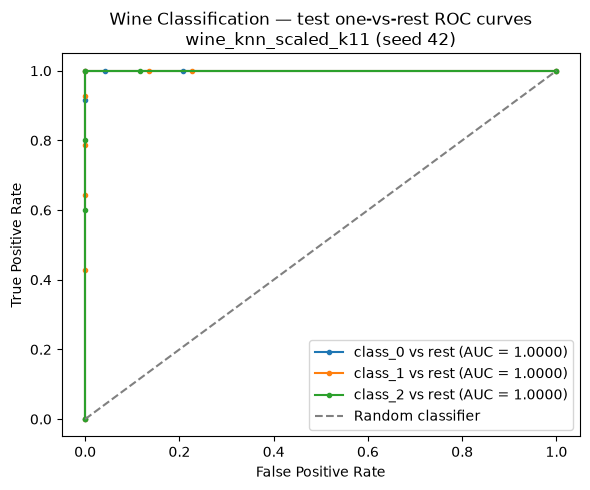

Class-specific AUCs: {'class_0': 1.0, 'class_1': 1.0, 'class_2': 1.0}
Macro one-vs-rest AUC: 1.0


In [29]:
assert list(selected_model.classes_) == class_labels
fig, ax = plt.subplots(figsize=(6, 5))
class_aucs = {}
for column, label in enumerate(class_labels):
    y_binary = (y_test == label).astype(int)
    fpr, tpr, _ = roc_curve(y_binary, y_test_proba[:, column])
    class_aucs[class_names[column]] = roc_auc_score(y_binary, y_test_proba[:, column])
    ax.plot(fpr, tpr, marker=".", label=f"{class_names[column]} vs rest (AUC = {class_aucs[class_names[column]]:.4f})")
ax.plot([0, 1], [0, 1], linestyle="--", color="grey", label="Random classifier")
macro_ovr_auc = roc_auc_score(y_test, y_test_proba, multi_class="ovr", average="macro", labels=class_labels)
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate",
       title=f"Wine Classification — test one-vs-rest ROC curves\n{selected_config_id} (seed 42)")
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(figure_dir / "roc_curve_test.png", dpi=150)
plt.show()
print("Class-specific AUCs:", {k: round(v, 4) for k, v in class_aucs.items()})
print("Macro one-vs-rest AUC:", round(macro_ovr_auc, 4))

**Decision threshold.** Lowering the threshold gives fewer false negatives but more false positives; raising it does the opposite. Each point on the ROC curve corresponds to one threshold; the curve shows this trade-off between the true positive rate and the false positive rate.

## 9.4 Error interpretation

In [30]:
misclassified = pd.DataFrame({
    "row_index": X_test.index,
    "actual": [class_names[class_labels.index(v)] for v in y_test],
    "predicted": [class_names[class_labels.index(v)] for v in y_test_pred],
})
for column, name in enumerate(class_names):
    misclassified[f"P({name})"] = y_test_proba[:, column].round(3)
misclassified = misclassified[misclassified["actual"] != misclassified["predicted"]]
print("Number of misclassified test samples:", len(misclassified), "of", len(y_test))
display(misclassified)

Number of misclassified test samples: 0 of 36


,row_index,actual,predicted,P(class_0),P(class_1),P(class_2)


**Interpretation (9.3–9.4).** All three one-vs-rest ROC curves reach the top-left corner, with class-specific AUCs of 1.0 and a macro one-vs-rest AUC of 1.0.

The selected classifier makes **no test errors**. This does not prove perfect generalisation, because the test set contains only 36 wines and the same configuration made errors on validation. **Limitation:** the validation subsets are small (18 samples) and the test result comes from a single seed (42).

# 10. K-Means Clustering

## 10.1 Fit the clustering model

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

N_CLUSTERS = 3


def safe_silhouette(features, cluster_labels):
    n_found = len(np.unique(cluster_labels))
    if n_found < 2 or n_found >= len(cluster_labels):
        return np.nan
    return silhouette_score(features, cluster_labels)


kmeans_records = []
kmeans_models_seed42 = {}

for seed in SEEDS:
    for representation in REPRESENTATIONS:
        X_train_rep = representations[seed][representation]["X_train"]
        X_val_rep = representations[seed][representation]["X_val"]
        y_val_seed = representations[seed]["y_val"]

        kmeans = KMeans(n_clusters=N_CLUSTERS, random_state=seed, n_init=10)
        kmeans.fit(X_train_rep)
        val_clusters = kmeans.predict(X_val_rep)
        val_silhouette = safe_silhouette(X_val_rep, val_clusters)

        kmeans_records.append({
            "dataset": DATASET_NAME,
            "run_id": f"{DATASET_NAME}_kmeans_{representation}_k{N_CLUSTERS}_s{seed}",
            "seed": seed,
            "representation": representation,
            "n_clusters": N_CLUSTERS,
            "n_init": 10,
            "train_inertia": kmeans.inertia_,
            "val_ari": adjusted_rand_score(y_val_seed, val_clusters),
            "val_silhouette": val_silhouette,
            "val_silhouette_defined": not np.isnan(val_silhouette),
            "val_cluster_counts": str(np.bincount(val_clusters, minlength=N_CLUSTERS).tolist()),
        })
        if seed == TEST_SEED:
            kmeans_models_seed42[representation] = kmeans

kmeans_runs = pd.DataFrame(kmeans_records)
kmeans_runs.to_csv(results_dir / f"{DATASET_NAME}_kmeans_runs.csv", index=False)
print("Wine Classification — K-Means run table ({} fits)".format(len(kmeans_runs)))
display(kmeans_runs.round(4))

Wine Classification — K-Means run table (6 fits)


,dataset,run_id,seed,representation,n_clusters,n_init,train_inertia,val_ari,val_silhouette,val_silhouette_defined,val_cluster_counts
0,wine,wine_kmeans_unscaled_k3_s42,42,unscaled,3,10,1.350496e+06,0.2828,0.4870,True,"[8, 4, 6]"
1,wine,wine_kmeans_scaled_k3_s42,42,scaled,3,10,8.747391e+02,1.0000,0.2516,True,"[6, 7, 5]"
2,wine,wine_kmeans_unscaled_k3_s52,52,unscaled,3,10,1.303675e+06,0.4006,0.5559,True,"[9, 5, 4]"
3,wine,wine_kmeans_scaled_k3_s52,52,scaled,3,10,8.904355e+02,1.0000,0.3010,True,"[7, 5, 6]"
4,wine,wine_kmeans_unscaled_k3_s62,62,unscaled,3,10,1.390754e+06,0.4006,0.6867,True,"[5, 4, 9]"
5,wine,wine_kmeans_scaled_k3_s62,62,scaled,3,10,8.722466e+02,1.0000,0.2726,True,"[6, 5, 7]"


In [32]:
kmeans_summary = kmeans_runs.groupby("representation", sort=False).agg(
    n_runs=("run_id", "size"),
    train_inertia_mean=("train_inertia", "mean"),
    train_inertia_std=("train_inertia", lambda s: s.std(ddof=1)),
    val_ari_mean=("val_ari", "mean"),
    val_ari_std=("val_ari", lambda s: s.std(ddof=1)),
    val_silhouette_mean=("val_silhouette", "mean"),
    val_silhouette_std=("val_silhouette", lambda s: s.std(ddof=1)),
    val_silhouette_valid_seeds=("val_silhouette_defined", "sum"),
).reset_index()
kmeans_summary.insert(0, "dataset", DATASET_NAME)
kmeans_summary.to_csv(results_dir / f"{DATASET_NAME}_kmeans_summary.csv", index=False)
print("Wine Classification — K-Means summary across 3 seeds")
display(kmeans_summary.round(4))

Wine Classification — K-Means summary across 3 seeds


,dataset,representation,n_runs,train_inertia_mean,train_inertia_std,val_ari_mean,val_ari_std,val_silhouette_mean,val_silhouette_std,val_silhouette_valid_seeds
0,wine,unscaled,3,1.348308e+06,43580.9098,0.3613,0.068,0.5765,0.1014,3
1,wine,scaled,3,8.791404e+02,9.8609,1.0000,0.000,0.2751,0.0248,3


**Interpretation (10.1).** Scaling strongly improves alignment with the true classes (mean validation ARI 0.361 unscaled vs. 1.000 scaled).
On the other hand, while the cluster quality score (silhouette) might appear high for unscaled data, this is misleading. This occurs because `proline` has very large values and dominates the calculations, causing the clusters to appear as though they are separated along only a single dimension. Therefore, a high score does not prove that an unscaled model is actually better.

## 10.2 Final cluster evaluation on the fixed test set

In [33]:
kmeans_test_records = []
test_cluster_predictions = {}

for representation in REPRESENTATIONS:
    kmeans = kmeans_models_seed42[representation]
    X_test_rep = test_representations[representation]
    test_clusters = kmeans.predict(X_test_rep)
    test_cluster_predictions[representation] = test_clusters

    counts = np.bincount(test_clusters, minlength=N_CLUSTERS)
    test_silhouette = safe_silhouette(X_test_rep, test_clusters)
    kmeans_test_records.append({
        "dataset": DATASET_NAME,
        "representation": representation,
        "evaluation_seed": TEST_SEED,
        "n_test": len(y_test),
        **{f"cluster_{c}_count": int(counts[c]) for c in range(N_CLUSTERS)},
        "test_ari": adjusted_rand_score(y_test, test_clusters),
        "test_silhouette": test_silhouette if not np.isnan(test_silhouette) else "N/A",
    })

    contingency = pd.crosstab(
        pd.Series([class_names[class_labels.index(v)] for v in y_test], name="Actual class"),
        pd.Series(test_clusters, name="Predicted cluster"),
    )
    print(f"Wine Classification — class vs. cluster contingency table ({representation}, seed 42, test set)")
    display(contingency)

kmeans_test = pd.DataFrame(kmeans_test_records)
kmeans_test.to_csv(results_dir / f"{DATASET_NAME}_kmeans_test.csv", index=False)
print("Wine Classification — K-Means final test evaluation")
display(kmeans_test.round(4))

Wine Classification — class vs. cluster contingency table (unscaled, seed 42, test set)


Predicted cluster,0,1,2
Actual class,,,
class_0,2,10,0
class_1,5,0,9
class_2,7,0,3


Wine Classification — class vs. cluster contingency table (scaled, seed 42, test set)


Predicted cluster,0,1,2
Actual class,,,
class_0,12,0,0
class_1,1,13,0
class_2,0,0,10


Wine Classification — K-Means final test evaluation


,dataset,representation,evaluation_seed,n_test,cluster_0_count,cluster_1_count,cluster_2_count,test_ari,test_silhouette
0,wine,unscaled,42,36,14,10,12,0.3733,0.4929
1,wine,scaled,42,36,13,13,10,0.9088,0.2711


## 10.3 Visualise and interpret the clusters

Seed-42 training data


,flavanoids,proline
class_0,2.951,1098.659
class_1,1.966,528.360
class_2,0.763,610.606


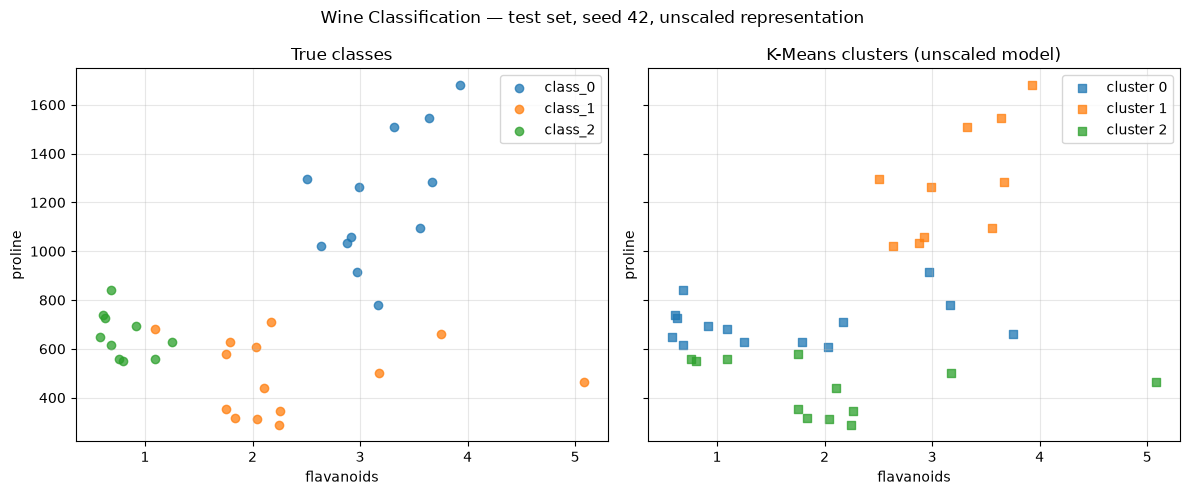

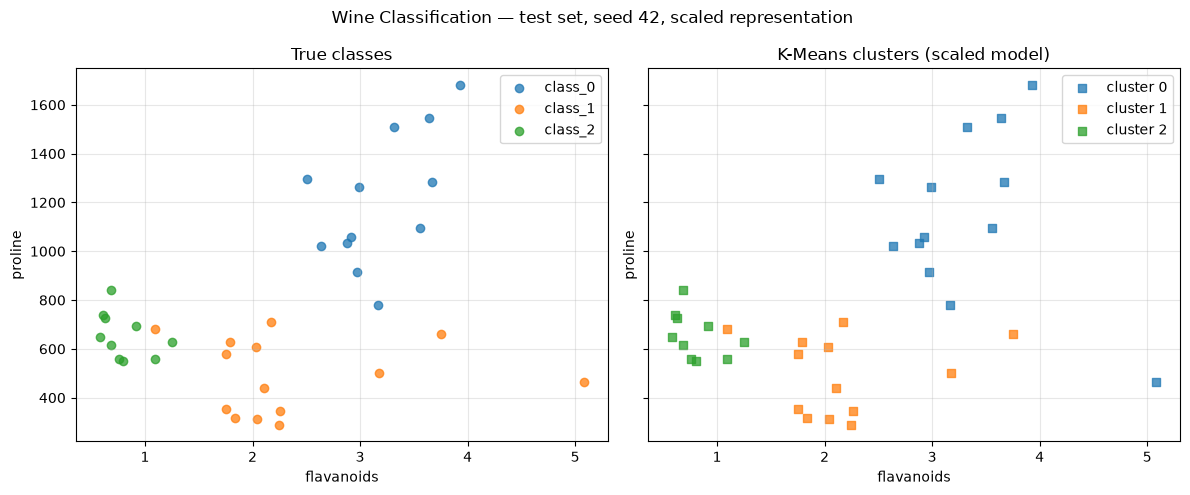

In [34]:
plot_features = ["flavanoids", "proline"]

training_class_means = (splits[TEST_SEED]["X_train"][plot_features]
                        .groupby(splits[TEST_SEED]["y_train"]).mean())
training_class_means.index = [class_names[class_labels.index(v)] for v in training_class_means.index]
print("Seed-42 training data")
display(training_class_means.round(3))

for representation in REPRESENTATIONS:
    fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharex=True, sharey=True)
    x_values = X_test[plot_features[0]]
    y_values = X_test[plot_features[1]]

    for label in class_labels:
        mask = (y_test == label).to_numpy()
        axes[0].scatter(x_values[mask], y_values[mask], label=class_names[class_labels.index(label)], alpha=0.75)
    axes[0].set_title("True classes")

    clusters = test_cluster_predictions[representation]
    for cluster_id in range(N_CLUSTERS):
        mask = clusters == cluster_id
        axes[1].scatter(x_values[mask], y_values[mask], label=f"cluster {cluster_id}", alpha=0.75, marker="s")
    axes[1].set_title(f"K-Means clusters ({representation} model)")

    for ax in axes:
        ax.set(xlabel=plot_features[0], ylabel=plot_features[1])
        ax.legend()
        ax.grid(alpha=0.3)
    fig.suptitle(f"Wine Classification — test set, seed 42, {representation} representation ")
    fig.tight_layout()
    fig.savefig(figure_dir / f"kmeans_{representation}_test_clusters.png", dpi=150)
    plt.show()

**Interpretation (10.2–10.3).**

- **Unscaled (test ARI 0.373):** cluster 1 contains only class_0 wines (10), but cluster 0 mixes all three classes (2 / 5 / 7) and cluster 2 mixes class_1 (9) and class_2 (3). In the training data, class_0 has much higher `proline` (mean ≈ 1,099) than class_1 (≈ 528) and class_2 (≈ 611), so unscaled K-Means separates class_0 but cannot separate class_1 from class_2.
- **Scaled (test ARI 0.909):** each cluster corresponds closely to one class; the only mixing is one class_1 wine assigned to the cluster that contains all 12 class_0 wines. The test silhouette is lower for scaled features (0.271 vs. 0.493), again because the two values come from different feature spaces.
- The plots use `flavanoids` and `proline` (training class means 2.95 / 1.97 / 0.76 and 1,099 / 528 / 611).
- **Information available during fitting:** the classifiers were trained with the true labels `y_train`, while K-Means received only the features.

# 12. Run inventory and combined result files

In [35]:
print(f"{DATASET_NAME}: classifier fits = {len(runs)}, K-Means fits = {len(kmeans_runs)}, "
      f"total model fits = {len(runs) + len(kmeans_runs)}")
assert len(runs) == 66 and len(kmeans_runs) == 6 and len(summary) == 22

expected_rows = {"classifier_runs": 132, "classifier_summary": 44, "classifier_test": 2,
                 "kmeans_runs": 12, "kmeans_summary": 4, "kmeans_test": 4}
datasets = ["breast_cancer", "wine"]
if all((results_dir / f"{d}_{name}.csv").exists() for d in datasets for name in expected_rows):
    inventory = []
    for name, n_expected in expected_rows.items():
        combined = pd.concat([pd.read_csv(results_dir / f"{d}_{name}.csv") for d in datasets],
                             ignore_index=True)
        combined.to_csv(f"{name}.csv", index=False)
        inventory.append({"file": f"{name}.csv", "rows": len(combined), "required_rows": n_expected,
                          "ok": len(combined) == n_expected})
    display(pd.DataFrame(inventory))
else:
    print("Run the other notebook as well to create the combined CSV files.")

wine: classifier fits = 66, K-Means fits = 6, total model fits = 72


,file,rows,required_rows,ok
0,classifier_runs.csv,132,132,True
1,classifier_summary.csv,44,44,True
2,classifier_test.csv,2,2,True
3,kmeans_runs.csv,12,12,True
4,kmeans_summary.csv,4,4,True
5,kmeans_test.csv,4,4,True
